# Parte 1 — O primeiro modelo em produção

**Banco Aurora · Prevenção a Fraudes** · entrega: **quarta-feira, 11/11, 23h59**

Leia antes o `demanda_parte1.md`: é o pedido do negócio. Este notebook é o roteiro técnico para atendê-lo.

**Como este notebook funciona**
- Cada seção diz **o que** fazer e **por quê**. O código é seu.
- Duas células vêm prontas (seção 0 e seção 10): elas são encanamento, não conteúdo.
- Tudo que será reutilizado nas partes 2 e 3 vai para arquivos `.py` (`features.py`, `monitoramento.py`), não fica só no notebook.
- Rode a partir da raiz do projeto, com o **MLflow** e o **sistema** no ar (veja o `README.md`).

**O que será avaliado nesta parte**
1. O contrato de features é respeitado no treino e na inferência.
2. O modelo está registrado e rastreável no MLflow, como `@champion`.
3. O threshold é justificado pelo custo de negócio.
4. O monitoramento está pronto **antes** do primeiro lote chegar.

O algoritmo é escolha sua. **Não existe ranking de performance**: existe um piso (seção 5) e existe a qualidade da justificativa.

## 0. Ambiente

Rode a célula abaixo. Se algo aparecer como `FALHOU`, resolva antes de seguir: o resto do notebook depende das quatro conexões.

In [1]:
# CÉLULA PRONTA — só rode. Tudo precisa aparecer como "ok".
import json
import urllib.request

import mlflow
import psycopg2

import config

for nome, uri in [("Postgres / antifraude", config.URI_BANCO_APP), ("Postgres / mlflow", config.URI_BANCO_MLFLOW)]:
    try:
        psycopg2.connect(uri).close()
        print(f"{nome:24} ok")
    except Exception as e:
        print(f"{nome:24} FALHOU -> {e}")

for nome, url in [("MLflow", f"{config.MLFLOW_TRACKING_URI}/health"), ("Sistema", f"{config.SISTEMA_URL}/saude")]:
    try:
        resp = urllib.request.urlopen(url, timeout=5).read().decode()
        print(f"{nome:24} ok -> {resp[:160]}")
    except Exception as e:
        print(f"{nome:24} FALHOU -> {e}")

mlflow.set_tracking_uri(config.MLFLOW_TRACKING_URI)
print("\ntracking uri:", mlflow.get_tracking_uri())

Postgres / antifraude    ok
Postgres / mlflow        ok
MLflow                   ok -> OK


Sistema                  ok -> {"sistema":"ok","contrato":"1.0","modelo":{"ok":true,"versao":"2","threshold":0.06,"run_id":"6fe2efed5e954b42b917ee5660534f89","descricao":"Escolhemos hist_grad

tracking uri: http://mlflow:5000


## 1. O contrato

O contrato (`contrato/contrato_features.yaml`) é o acordo com o time de Plataforma: as 13 features que o sistema de produção entrega, com tipo, regra de cálculo e valores permitidos. **O sistema rejeita qualquer lote que não o respeite**, e o seu modelo vai receber exatamente isso — nada mais.

**Faça**
1. Leia o YAML com `yaml.safe_load` e monte, a partir dele (não digitando à mão), a lista das features na ordem do contrato, separando categóricas e numéricas.
2. Carregue `dados/transacoes_semanas_01_12.csv` e `dados/rotulos_semanas_01_12.csv` e junte os dois pela `id_transacao`. Garanta que a junção é 1 para 1 e que nenhuma linha se perdeu.
3. Escreva uma validação do histórico contra o contrato: colunas presentes, tipos, valores fora da lista nas categóricas, valores fora de `min`/`max`, nulos. O histórico passa?

> Por que validar um dado que "veio do próprio banco"? Porque o modelo vai aprender o que estiver aqui. Se o treino tiver algo que a produção não terá (ou o contrário), o erro só aparece depois, em produção.

In [2]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import features
import monitoramento as mon
import workflow as wf

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 20)
contrato = features.carregar_contrato()
nomes, categoricas, numericas = features.colunas_contrato(contrato)
assert len(nomes) == 13
display(pd.DataFrame(contrato["features"]).fillna("—"))
print("Categóricas:", categoricas)
print("Numéricas/booleanas:", numericas)

,nome,tipo,min,regra,max,valores
0,valor_transacao,float,0.01,"Valor da transação em reais, 2 casas decimais.",—,—
1,hora_transacao,int,0.0,Hora da transação no horário de Brasília.,23.0,—
2,dia_semana,int,0.0,"0 = segunda-feira, 6 = domingo.",6.0,—
3,canal,categoria,—,Canal de origem da transação.,—,"[pix, cartao_presencial, cartao_online]"
4,dispositivo_novo,bool,—,1 se é o primeiro uso do dispositivo nos últim...,—,—
5,qtd_transacoes_1h,int,0.0,Transações do mesmo cliente na hora anterior (...,—,—
6,valor_medio_30d,float,0.01,Valor médio das transações do cliente nos últi...,—,—
7,razao_valor_media,float,0.0,valor_transacao / valor_medio_30d.,—,—
8,distancia_ultima_transacao_km,float,0.0,Distância em km até o local da transação anter...,—,—
9,idade_conta_dias,int,0.0,Dias desde a abertura da conta.,—,—


Categóricas: ['canal', 'categoria_estabelecimento', 'uf_cliente']
Numéricas/booleanas: ['valor_transacao', 'hora_transacao', 'dia_semana', 'dispositivo_novo', 'qtd_transacoes_1h', 'valor_medio_30d', 'razao_valor_media', 'distancia_ultima_transacao_km', 'idade_conta_dias', 'destinatario_novo']


In [3]:
historico, auditoria = wf.carregar_historico(contrato)
display(auditoria)
print(f"Junção 1:1: {len(historico):,} transações; nenhuma linha perdida.")
print("Nulos nas features:", int(historico[nomes].isna().sum().sum()))
print("Todas as semanas passam no contrato, na razão valor/média e na consistência de hora/dia.")

,semana,linhas,erros,ok
0,1,20160,,True
1,2,19811,,True
2,3,20283,,True
3,4,19995,,True
4,5,20318,,True
5,6,20479,,True
6,7,20307,,True
7,8,19706,,True
8,9,20006,,True
9,10,19822,,True


Junção 1:1: 240,384 transações; nenhuma linha perdida.
Nulos nas features: 0
Todas as semanas passam no contrato, na razão valor/média e na consistência de hora/dia.


In [4]:
# data_contestacao é ausente nos legítimos, e é PROIBIDA como feature.
assert not set(nomes) & {"fraude", "id_cliente", "semana", "id_transacao", "data_contestacao", "data_transacao"}
display(historico.groupby("canal").agg(n=("fraude", "size"), taxa_fraude=("fraude", "mean"),
                                      valor_total=("valor_transacao", "sum")))
wf.salvar_json(wf.ARTEFATOS / "linhagem.json", wf.linhagem(contrato))

,n,taxa_fraude,valor_total
canal,,,
cartao_online,60145,0.019802,14133302.62
cartao_presencial,71765,0.009726,11828678.18
pix,108474,0.014833,19040623.63


## 2. Divisão temporal

A regra combinada com o negócio: **treino nas semanas 1 a 10, validação nas semanas 11 e 12**.

**Faça**
1. Separe os dois conjuntos pela coluna `semana`.
2. Mostre a taxa de fraude por semana e o tamanho de cada conjunto.
3. Responda em uma célula de texto: por que uma divisão aleatória (`train_test_split`) seria um erro aqui?

In [5]:
treino = historico[historico.semana.between(1, 10)].copy()
validacao = historico[historico.semana.isin([11, 12])].copy()
assert treino.semana.max() < validacao.semana.min()
assert set(treino.id_transacao).isdisjoint(validacao.id_transacao)
semanal = historico.groupby("semana").agg(n=("fraude", "size"), fraudes=("fraude", "sum"),
                                           taxa_fraude=("fraude", "mean"))
semanal["conjunto"] = np.where(semanal.index <= 10, "treino", "validação")
display(semanal)
print(f"Treino: {len(treino):,}; validação: {len(validacao):,}")
semanal.to_csv(wf.ARTEFATOS / "populacao_semanal.csv")

,n,fraudes,taxa_fraude,conjunto
semana,,,,
1,20160,297,0.014732,treino
2,19811,282,0.014235,treino
3,20283,249,0.012276,treino
4,19995,263,0.013153,treino
5,20318,371,0.018260,treino
6,20479,298,0.014551,treino
7,20307,277,0.013641,treino
8,19706,306,0.015528,treino
9,20006,234,0.011696,treino


Treino: 200,887; validação: 39,497


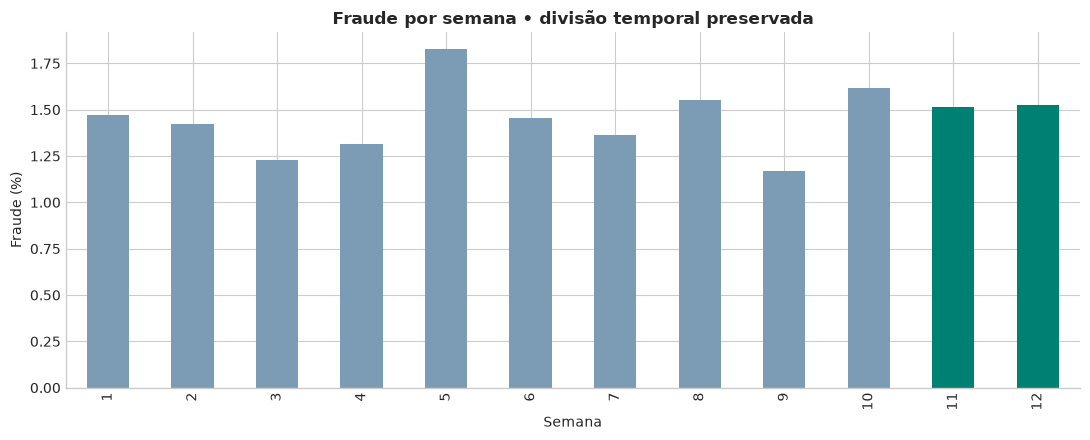

In [6]:
ax = (100 * semanal.taxa_fraude).plot.bar(color=["#7c9bb5"] * 10 + ["#007f73"] * 2)
ax.set(title="Fraude por semana • divisão temporal preservada", xlabel="Semana", ylabel="Fraude (%)")
plt.tight_layout()
plt.savefig(wf.ARTEFATOS / "fraude_semanal.png", dpi=160)
plt.show()

**Por que não dividir aleatoriamente?** O banco usa passado para decidir sobre
transações futuras. Em uma divisão aleatória, transações de semanas mais recentes
ajudariam a prever semanas antigas, mascarando mudanças de comportamento e
produzindo uma avaliação que não representa a operação. O mesmo cliente pode
aparecer em semanas diferentes; isso é permitido, mas seus IDs não entram no modelo.

As semanas 1–10 ajustam inclusive o pré-processamento. As semanas 11–12 servem
exclusivamente para comparar os candidatos e escolher o threshold pedido no roteiro.
Portanto, os custos reportados são **estimativas de validação usadas na seleção**,
com algum otimismo; não constituem teste independente nem garantia para semanas futuras.
O histórico foi fornecido com rótulos fechados. Em uma simulação cronológica real,
é obrigatório esperar uma semana pelo fechamento de cada lote, inclusive para treinar.

## 3. Pré-processamento em `features.py`

Escreva no arquivo `features.py` (não no notebook) o que transforma as 13 features cruas na entrada do seu algoritmo. Depois, importe aqui.

**Requisitos**
- O pré-processamento precisa ser parte do modelo que você registra (um `Pipeline` do scikit-learn). Em produção, o sistema entrega as features cruas e chama `predict_proba` — ele não transforma nada.
- As listas de colunas e de categorias vêm **do contrato**, não do que apareceu no treino. Pense no que acontece se uma UF que não está no treino aparecer em produção.
- Se o seu pipeline usar classes ou funções suas, o modelo precisa ser registrado com `code_paths=["features.py"]`.

> Dica: depois de editar o `features.py`, use `importlib.reload(features)` ou reinicie o kernel.

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier

alternativas = {
    "regressao_logistica": LogisticRegression(C=1.0, class_weight="balanced", max_iter=1000,
                                             solver="lbfgs", random_state=wf.SEED),
    "hist_gradient_boosting": HistGradientBoostingClassifier(
        learning_rate=0.08, max_iter=220, max_leaf_nodes=15, min_samples_leaf=40,
        l2_regularization=2.0, early_stopping=False, random_state=wf.SEED),
}
# Hiperparâmetros fixados previamente; sem busca repetida nas semanas 11–12.
# early_stopping=False evita uma divisão aleatória interna.
display(features.criar_pipeline(alternativas["regressao_logistica"], contrato))

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('contrato', ...), ('preprocessamento', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,contrato,"{'changelog': [{'data': '2026-11-06', 'mudanca': 'Versão inicial do contrato.', 'versao': '1.0'}], 'features': [{'min': 0.01, 'nome': 'valor_transacao', 'regra': 'Valor da transação em reais, 2 casas decimais.', 'tipo': 'float'}, {'max': 23, 'min': 0, 'nome': 'hora_transacao', 'regra': 'Hora da transação no horário de Brasília.', ...}, ...], 'metadados': ['id_transacao', 'id_cliente', ...], 'regras': [], ...}"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...), ('categoricas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excl

In [8]:
display(Markdown("""Todo o tratamento fica no Pipeline registrado: validação das 13
entradas, log1p e escala nas numéricas, one-hot nas categóricas e classificador.
O one-hot conhece **todos os domínios do YAML**, inclusive UFs ausentes no treino;
uma categoria fora do contrato é rejeitada. Não reconstruímos histórico de clientes
nem recalculamos agregados: usamos exatamente as features cruas da Plataforma.

A regressão logística oferece uma referência simples e regularizada; o boosting
captura interações e efeitos não lineares. O balanceamento da regressão altera a
escala dos scores, por isso o corte é selecionado separadamente para cada modelo.
Não interpretamos esses scores como probabilidades calibradas de risco."""))

Todo o tratamento fica no Pipeline registrado: validação das 13
entradas, log1p e escala nas numéricas, one-hot nas categóricas e classificador.
O one-hot conhece **todos os domínios do YAML**, inclusive UFs ausentes no treino;
uma categoria fora do contrato é rejeitada. Não reconstruímos histórico de clientes
nem recalculamos agregados: usamos exatamente as features cruas da Plataforma.

A regressão logística oferece uma referência simples e regularizada; o boosting
captura interações e efeitos não lineares. O balanceamento da regressão altera a
escala dos scores, por isso o corte é selecionado separadamente para cada modelo.
Não interpretamos esses scores como probabilidades calibradas de risco.

## 4. Pelo menos dois modelos, tudo no MLflow

Treine **pelo menos dois algoritmos** diferentes, cada um em uma run do MLflow.

**Faça**
1. Crie (ou use) um experimento com nome que você reconheça depois.
2. Em cada run, registre:
   - **parâmetros**: algoritmo, hiperparâmetros relevantes, semanas de treino e de validação, versão do contrato;
   - **métricas na validação**: PR-AUC, recall, precision e **custo** (seção 5);
   - **o modelo** (`mlflow.sklearn.log_model`), com assinatura (`infer_signature`) e um `input_example`.
3. Compare as runs na interface do MLflow.

> Use PR-AUC e não ROC-AUC para comparar ranking: com 1,5% de fraude, a ROC-AUC fica alta até para modelos ruins.

In [9]:
candidatos = []
for nome, estimador in alternativas.items():
    candidatos.append(wf.treinar_candidato(nome, estimador, treino, validacao, contrato))

2026/11/10 14:22:17 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet



/usr/local/lib/python3.12/site-packages/mlflow/types/utils.py:435: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


regressao_logistica: PR-AUC=0.6988; threshold=0.70; custo R$ 36,297.05 / 2 semanas; run=aae6ce1277f54b0fbcda808e068189a2
🏃 View run regressao_logistica at: http://mlflow:5000/#/experiments/1/runs/aae6ce1277f54b0fbcda808e068189a2
🧪 View experiment at: http://mlflow:5000/#/experiments/1


hist_gradient_boosting: PR-AUC=0.8363; threshold=0.06; custo R$ 24,848.61 / 2 semanas; run=4398e4b800f14df1a95d6cd1fec8ee64
🏃 View run hist_gradient_boosting at: http://mlflow:5000/#/experiments/1/runs/4398e4b800f14df1a95d6cd1fec8ee64
🧪 View experiment at: http://mlflow:5000/#/experiments/1


/usr/local/lib/python3.12/site-packages/mlflow/types/utils.py:435: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


In [10]:
resumo_runs = pd.DataFrame([{"algoritmo": c["nome"], "run_id": c["run_id"],
                             "pr_auc": c["metricas"]["pr_auc"],
                             "recall": c["metricas"]["recall"],
                             "precision": c["metricas"]["precision"],
                             "custo": c["metricas"]["custo"],
                             "threshold": c["metricas"]["threshold"]} for c in candidatos])
display(resumo_runs)
resumo_runs.to_csv(wf.ARTEFATOS / "runs_comparadas.csv", index=False)
display(Markdown("Runs disponíveis no [MLflow local](http://127.0.0.1:5000). Compare custo, PR-AUC e threshold no experimento Aurora."))

,algoritmo,run_id,pr_auc,recall,precision,custo,threshold
0,regressao_logistica,aae6ce1277f54b0fbcda808e068189a2,0.698811,0.838333,0.280535,36297.05,0.70
1,hist_gradient_boosting,4398e4b800f14df1a95d6cd1fec8ee64,0.836347,0.848333,0.510020,24848.61,0.06


Runs disponíveis no [MLflow local](http://127.0.0.1:5000). Compare custo, PR-AUC e threshold no experimento Aurora.

In [11]:
# O modelo que custa menos é escolhido, sem usar acurácia como critério.
campeao = min(candidatos, key=lambda c: (c["metricas"]["custo"], c["nome"]))
threshold = float(campeao["metricas"]["threshold"])
print("Vencedor:", campeao["nome"], "| threshold:", threshold)

Vencedor: hist_gradient_boosting | threshold: 0.06


## 5. Threshold pelo custo

O `predict_proba` devolve um score. O **threshold** é o corte: `score >= threshold` → bloquear. O padrão de 0,5 não tem nada a ver com o problema do banco.

**Custo de um conjunto de decisões** = soma do **valor** das fraudes aprovadas + **R$ 15** × legítimas bloqueadas.

**Faça**
1. Escreva a função de custo (ela vai para o `monitoramento.py` na seção 9; pode começar aqui).
2. Para cada modelo, varra thresholds de 0,01 a 0,99 na **validação** e escolha o de menor custo. Faça o gráfico custo × threshold.
3. No threshold escolhido, mostre recall, precision e custo. Registre o threshold e o custo como métricas da run.
4. Mostre a comparação com o **piso** pedido pelo negócio:
   - aprovar tudo;
   - a regra atual: bloquear todo Pix acima de R$ 1.000;
   - o próprio modelo com threshold 0,5.

In [12]:
# Custo: valor das fraudes aprovadas + 15 reais por legítima bloqueada.
from monitoramento import custo_decisoes
assert custo_decisoes([1, 0, 1, 0], [0, 1, 1, 0], [200, 80, 900, 20]) == 215.0
for c in candidatos:
    display(c["curva"].head(5)[["threshold", "custo", "recall", "precision", "legitimas_bloqueadas"]])

,threshold,custo,recall,precision,legitimas_bloqueadas
0,0.70,36297.05,0.838333,0.280535,1290
1,0.77,36775.70,0.816667,0.344101,934
2,0.69,37042.40,0.843333,0.270878,1362
3,0.76,37525.70,0.816667,0.332429,984
4,0.80,37565.75,0.800000,0.373250,806


,threshold,custo,recall,precision,legitimas_bloqueadas
0,0.06,24848.61,0.848333,0.510020,489
1,0.13,24856.32,0.816667,0.694051,216
2,0.07,25096.85,0.841667,0.542427,426
3,0.12,25184.66,0.820000,0.671214,241
4,0.05,25240.19,0.861667,0.464093,597


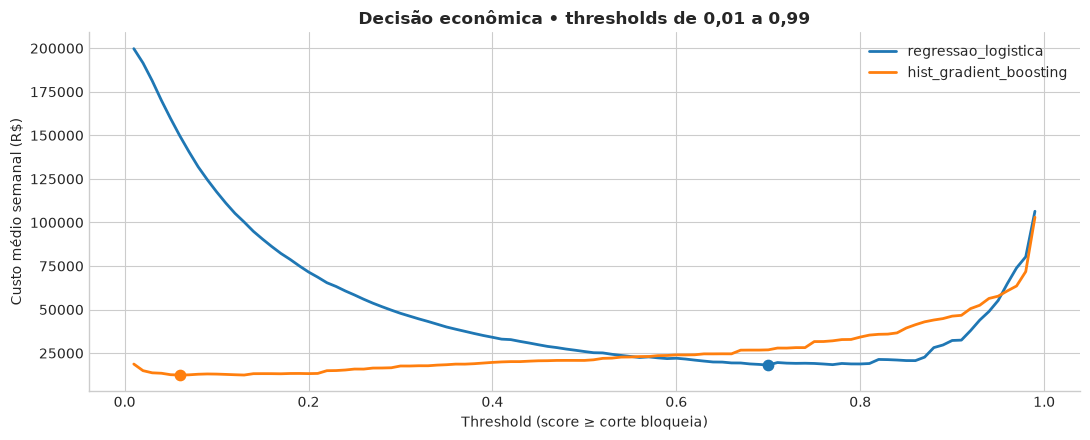

🏃 View run hist_gradient_boosting at: http://mlflow:5000/#/experiments/1/runs/4398e4b800f14df1a95d6cd1fec8ee64
🧪 View experiment at: http://mlflow:5000/#/experiments/1


In [13]:
fig, ax = plt.subplots()
for c in candidatos:
    curva = c["curva"].sort_values("threshold")
    ax.plot(curva.threshold, curva.custo / 2, label=c["nome"], linewidth=2)
    ax.scatter(c["metricas"]["threshold"], c["metricas"]["custo"] / 2, s=55)
ax.set(xlabel="Threshold (score ≥ corte bloqueia)", ylabel="Custo médio semanal (R$)",
       title="Decisão econômica • thresholds de 0,01 a 0,99")
ax.legend()
plt.tight_layout()
plt.savefig(wf.ARTEFATOS / "custo_threshold.png", dpi=160)
plt.show()
with mlflow.start_run(run_id=campeao["run_id"]):
    mlflow.log_artifact(str(wf.ARTEFATOS / "custo_threshold.png"), "avaliacao")

In [14]:
comparacao = wf.comparar(candidatos, validacao)
display(comparacao[["alternativa", "threshold", "custo", "custo_medio_semanal", "recall", "precision"]])
piso_aprovar, piso_regra = comparacao.iloc[0].custo, comparacao.iloc[1].custo
assert campeao["metricas"]["custo"] < min(piso_aprovar, piso_regra, campeao["padrao"]["custo"]), "Piso de negócio não atendido"
por_semana = pd.DataFrame([{"semana": int(s), **mon.metricas(g.fraude,
    campeao["modelo"].predict_proba(g[nomes])[:, 1], g.valor_transacao, threshold),
    "custo_regra": custo_decisoes(g.fraude, (g.canal == "pix") & (g.valor_transacao > 1000), g.valor_transacao),
    "custo_aprovar": float(g.loc[g.fraude == 1, "valor_transacao"].sum()),
    "custo_padrao_05": mon.metricas(g.fraude, campeao["modelo"].predict_proba(g[nomes])[:, 1], g.valor_transacao, 0.5)["custo"]}
    for s, g in validacao.groupby("semana")])
display(por_semana)
por_semana.to_csv(wf.ARTEFATOS / "custos_semanais.csv", index=False)
assert (por_semana.custo < por_semana[["custo_regra", "custo_aprovar", "custo_padrao_05"]].min(axis=1)).all()
m = campeao["metricas"]
def brl(x):
    return "R$ " + f"{x:,.2f}".replace(",", "_").replace(".", ",").replace("_", ".")
economia = piso_regra - m["custo"]
justificativa = (
    f"Escolhemos {campeao['nome']}, com corte {threshold:.2f}, pelo menor custo observado. "
    f"Nas semanas 11–12, o custo total é {brl(m['custo'])}, média de {brl(m['custo']/2)} por semana. "
    f"A regra Pix acima de R$ 1.000 custa {brl(piso_regra/2)} por semana; a economia média é "
    f"{brl(economia/2)} por semana ({economia/piso_regra:.1%}). Aprovar tudo custa {brl(piso_aprovar/2)} "
    f"por semana; o mesmo modelo com corte 0,5 custa {brl(campeao['padrao']['custo']/2)}. "
    f"No total das duas semanas, {int(m['legitimas_bloqueadas'])} transações legítimas são bloqueadas "
    f"({brl(15*m['legitimas_bloqueadas'])} de atrito), e passam {int(m['fraudes_aprovadas'])} fraudes "
    f"({brl(m['fraude_perdida'])}). Recall {m['recall']:.1%}, precision {m['precision']:.1%}, "
    f"PR-AUC (average precision) {m['pr_auc']:.4f}, bloqueio {m['taxa_bloqueio']:.1%}. "
    "Esses números são de validação usada na seleção, não promessa de economia futura. "
    "Bloquear encaminha à verificação no app; não significa cancelar a transação."
)
(wf.ARTEFATOS / "justificativa.txt").write_text(justificativa, encoding="utf-8")
display(Markdown(justificativa))

,alternativa,threshold,custo,custo_medio_semanal,recall,precision
0,Aprovar tudo,NaN,376035.53,188017.765,NaN,NaN
1,Regra Pix > R$ 1.000,NaN,225349.79,112674.895,NaN,NaN
2,regressao_logistica | custo mínimo,0.70,36297.05,18148.525,0.838333,0.280535
3,"regressao_logistica | padrão 0,5",0.50,51862.40,25931.200,0.881667,0.157675
4,hist_gradient_boosting | custo mínimo,0.06,24848.61,12424.305,0.848333,0.510020
5,"hist_gradient_boosting | padrão 0,5",0.50,41621.25,20810.625,0.701667,0.909287


,semana,n,fraudes,taxa_fraude,recall,precision,pr_auc,custo,custo_por_1000,legitimas_bloqueadas,fraudes_aprovadas,fraude_perdida,fraude_evitada,taxa_bloqueio,valor_bloqueado,custo_regra,custo_aprovar,custo_padrao_05
0,11,20399,309,0.015148,0.851133,0.511673,0.835781,10550.47,517.205255,251,46,6785.47,170243.80,0.025197,247752.85,102820.44,177029.27,17518.68
1,12,19098,291,0.015237,0.845361,0.508264,0.837742,14298.14,748.672112,238,45,10728.14,188278.12,0.025343,253295.37,122529.35,199006.26,24102.57


Escolhemos hist_gradient_boosting, com corte 0.06, pelo menor custo observado. Nas semanas 11–12, o custo total é R$ 24.848,61, média de R$ 12.424,30 por semana. A regra Pix acima de R$ 1.000 custa R$ 112.674,90 por semana; a economia média é R$ 100.250,59 por semana (89.0%). Aprovar tudo custa R$ 188.017,77 por semana; o mesmo modelo com corte 0,5 custa R$ 20.810,62. No total das duas semanas, 489 transações legítimas são bloqueadas (R$ 7.335,00 de atrito), e passam 91 fraudes (R$ 17.513,61). Recall 84.8%, precision 51.0%, PR-AUC (average precision) 0.8363, bloqueio 2.5%. Esses números são de validação usada na seleção, não promessa de economia futura. Bloquear encaminha à verificação no app; não significa cancelar a transação.

## 6. A escolha

Em uma célula de texto, escolha o modelo que vai para produção e justifique **em linguagem de custo**, como você explicaria para a Helena: quanto ele custa por semana na validação, quanto economiza em relação à regra atual, quantos clientes legítimos ele incomoda e quanta fraude ainda passa.

Não vale "porque teve a maior PR-AUC". Vale usar a PR-AUC como argumento de apoio.

Escolhemos hist_gradient_boosting, com corte 0.06, pelo menor custo observado. Nas semanas 11–12, o custo total é R$ 24.848,61, média de R$ 12.424,30 por semana. A regra Pix acima de R$ 1.000 custa R$ 112.674,90 por semana; a economia média é R$ 100.250,59 por semana (89.0%). Aprovar tudo custa R$ 188.017,77 por semana; o mesmo modelo com corte 0,5 custa R$ 20.810,62. No total das duas semanas, 489 transações legítimas são bloqueadas (R$ 7.335,00 de atrito), e passam 91 fraudes (R$ 17.513,61). Recall 84.8%, precision 51.0%, PR-AUC (average precision) 0.8363, bloqueio 2.5%. Esses números são de validação usada na seleção, não promessa de economia futura. Bloquear encaminha à verificação no app; não significa cancelar a transação.

## 7. Registro e promoção

**Faça**
1. Registre o modelo escolhido no Model Registry com o nome **`antifraude`** (é o nome que o sistema procura).
2. Na **versão** registrada (não na run), grave as tags:
   - `threshold` — o corte escolhido na seção 5 (o sistema lê daqui);
   - `motivo` — uma frase curta, ex.: `v1.0.0 - primeiro modelo em produção` (aparece no histórico de trocas do sistema).
3. Escreva uma **descrição** para a versão: algoritmo, threshold e por que foi escolhido.
4. Aponte o alias **`champion`** para essa versão.

Use o `MlflowClient` para os passos 2 a 4.

In [15]:
# A referência vai para a run ANTES de expor a versão como champion.
referencia = validacao.copy()
referencia["score"] = campeao["scores"]
referencia["bloqueada"] = referencia.score >= threshold
referencia["threshold"] = threshold
pasta_ref = wf.ARTEFATOS / "referencia"
pasta_ref.mkdir(exist_ok=True)
referencia.to_csv(pasta_ref / "referencia.csv", index=False)
wf.salvar_json(pasta_ref / "metadados.json", {
    "run_id": campeao["run_id"], "contrato_versao": contrato["versao"], "semanas": [11, 12],
    "threshold": threshold, "n": len(referencia), "rotulos_fechados": True,
    "features": nomes, "limites_alerta": mon.LIMITES,
    "origem": "validação histórica, não lote futuro", "linhagem": wf.linhagem(contrato)})
with mlflow.start_run(run_id=campeao["run_id"]):
    mlflow.log_artifacts(str(pasta_ref), artifact_path="referencia")
    mlflow.log_artifact(str(wf.ARTEFATOS / "comparacao.csv"), "avaliacao")
    mlflow.log_artifact(str(wf.ARTEFATOS / "custos_semanais.csv"), "avaliacao")
    mlflow.log_text(justificativa, "justificativa.txt")
mv = wf.registrar_campeao(campeao, justificativa, contrato)
print("Champion:", config.NOME_MODELO, "versão", mv.version, "| run", mv.run_id)
display(dict(mv.tags))

Registered model 'antifraude' already exists. Creating a new version of this model...
2026/11/10 14:22:26 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: antifraude, version 3


🏃 View run hist_gradient_boosting at: http://mlflow:5000/#/experiments/1/runs/4398e4b800f14df1a95d6cd1fec8ee64
🧪 View experiment at: http://mlflow:5000/#/experiments/1
Champion: antifraude versão 3 | run 4398e4b800f14df1a95d6cd1fec8ee64


Created version '3' of model 'antifraude'.


{'threshold': '0.06',
 'motivo': 'v1.0.0 - menor custo de validação entre os candidatos',
 'contrato_versao': '1.0',
 'versao_semantica': '1.0.0'}

In [16]:
from mlflow.tracking import MlflowClient
cli = MlflowClient()
registrada = cli.get_model_version_by_alias(config.NOME_MODELO, "champion")
assert registrada.run_id == campeao["run_id"]
assert float(registrada.tags["threshold"]) == threshold
assert registrada.description and registrada.tags["motivo"]
assert cli.list_artifacts(registrada.run_id, "referencia")
print("Registro, tags na VERSÃO, descrição, alias e referência conferidos.")

Registro, tags na VERSÃO, descrição, alias e referência conferidos.


## 8. O sistema está usando o seu modelo?

Abra http://127.0.0.1:8000/modelo: deve aparecer a sua versão e o seu threshold.

**Faça**
1. Pegue 5 transações da semana 12 (só as 13 features) e mande para `POST /predict` do sistema (lista de objetos JSON).
2. Pontue as mesmas 5 transações com o modelo carregado do MLflow (`models:/antifraude@champion`) no notebook.
3. Confira que os scores são **idênticos** e que a decisão (bloquear ou não) bate com o seu threshold.

> Se os scores forem diferentes, há alguma transformação acontecendo de um jeito no notebook e de outro em produção. É exatamente o tipo de bug que o contrato existe para evitar.

In [17]:
paridade = wf.validar_serving(validacao, contrato)
display(paridade)
print("5/5 scores idênticos após a serialização da API (seis casas); decisões idênticas.")
print("A API original arredonda score. A seguir verificamos também a precisão completa dos lotes.")

,score,bloquear,threshold,versao_modelo,score_mlflow_integral,score_mlflow_6_casas
0,0.092886,True,0.06,3,0.092886,0.092886
1,0.992574,True,0.06,3,0.992574,0.992574
2,0.000307,False,0.06,3,0.000307,0.000307
3,0.045649,False,0.06,3,0.045649,0.045649
4,0.168949,True,0.06,3,0.168949,0.168949


5/5 scores idênticos após a serialização da API (seis casas); decisões idênticas.
A API original arredonda score. A seguir verificamos também a precisão completa dos lotes.


In [18]:
# Dados históricos de demonstração: não simulamos a chegada de semanas futuras.
display(wf.carregar_validacao_sistema(validacao))
display(wf.verificar_lote_integral(validacao, campeao, contrato))
import requests
saude = requests.get(f"{config.SISTEMA_URL}/saude", timeout=60).json()
assert saude["modelo"]["ok"] and saude["modelo"]["versao"] == mv.version
display(saude)
wf.salvar_json(wf.ARTEFATOS / "saude.json", saude)

[{'semana': 11,
  'transacoes': 20399,
  'pct_bloqueado': 0.025197313593803616,
  'versao_modelo': '3',
  'msg': 'Semana 11 repontuada pelo modelo v3. A predição anterior continua no banco; o painel passa a usar esta.'},
 {'semana': 12,
  'transacoes': 19098,
  'pct_bloqueado': 0.025342967850036653,
  'versao_modelo': '3',
  'msg': 'Semana 12 repontuada pelo modelo v3. A predição anterior continua no banco; o painel passa a usar esta.'}]

,semana,n,erro_maximo,decisoes_identicas
0,11,20399,1.110223e-16,True
1,12,19098,1.110223e-16,True


{'sistema': 'ok',
 'contrato': '1.0',
 'modelo': {'ok': True,
  'versao': '3',
  'threshold': 0.06,
  'run_id': '4398e4b800f14df1a95d6cd1fec8ee64',
  'descricao': 'Escolhemos hist_gradient_boosting, com corte 0.06, pelo menor custo observado. Nas semanas 11–12, o custo total é R$ 24.848,61, média de R$ 12.424,30 por semana. A regra Pix acima de R$ 1.000 custa R$ 112.674,90 por semana; a economia média é R$ 100.250,59 por semana (89.0%). Aprovar tudo custa R$ 188.017,77 por semana; o mesmo modelo com corte 0,5 custa R$ 20.810,62. No total das duas semanas, 489 transações legítimas são bloqueadas (R$ 7.335,00 de atrito), e passam 91 fraudes (R$ 17.513,61). Recall 84.8%, precision 51.0%, PR-AUC (average precision) 0.8363, bloqueio 2.5%. Esses números são de validação usada na seleção, não promessa de economia futura. Bloquear encaminha à verificação no app; não significa cancelar a transação.'}}

## 9. Monitoramento baseline

A partir de quarta-feira chegam as semanas novas, uma por vez, e os rótulos de cada semana chegam só uma semana depois. O seu monitoramento precisa estar pronto **antes**, para que você perceba problemas sem esperar o negócio reclamar.

### 9.1 Referência
A referência é a "foto" de como os dados e os scores eram quando o modelo foi aprovado: as features da **validação** (semanas 11 e 12), o score do modelo escolhido e o rótulo.
- Salve a referência em arquivo e registre-a como **artefato da run do modelo campeão**, na pasta `referencia/` (`mlflow.log_artifacts(..., artifact_path="referencia", run_id=...)`). Assim, trocou o modelo, trocou a referência.

### 9.2 `monitoramento.py`
Escreva funções reutilizáveis que recebam a referência e um lote e devolvam tabelas legíveis:
- **Drift das features contínuas e do score**: teste **KS**, reportando a **estatística D** e o p-valor.
- **Drift das categóricas e booleanas** (e da hora): qui-quadrado ou comparação de proporções.
- **Saída do modelo**: taxa de bloqueio e valor bloqueado.
- **Performance, para quando o rótulo chegar**: recall, precision, PR-AUC e custo — **globais e por segmento** (uma coluna à sua escolha, ex.: `canal`).

### 9.3 Relatório zero
Rode o monitoramento comparando a **semana 11 com a semana 12** (as duas são da validação, nada mudou de propósito entre elas).
- Olhe os p-valores e as estatísticas. Algum p-valor é minúsculo mesmo sem nenhuma mudança relevante? Por quê?
- Defina e **justifique por escrito** os seus limites de alerta (ex.: D > 0,1). Eles valem para as próximas partes.

> O que você vai receber a cada semana: o CSV de transações (que você envia em **Lotes** no sistema) e, a partir da segunda semana, o CSV de rótulos da semana anterior (em **Rótulos**). Os dados já pontuados ficam em `GET /api/semanas/{n}/dados.csv`, com o score e, quando houver, o rótulo. É daí que o seu monitoramento vai ler.

In [19]:
semana11 = referencia[referencia.semana == 11]
semana12 = referencia[referencia.semana == 12]
zero = mon.relatorio(semana11, semana12, contrato, threshold, rotulos_fechados=True)
pasta_zero = wf.ARTEFATOS / "relatorio_zero"
pasta_zero.mkdir(exist_ok=True)
for nome, tabela in zero.items():
    tabela.to_csv(pasta_zero / f"{nome}.csv", index=False)
    print("\n", nome.upper())
    display(tabela)


 QUALIDADE


,origem,ok,detalhe
0,referencia,True,contrato válido
1,lote,True,contrato válido



 DRIFT


,feature,teste,estatistica,p_valor,efeito,limite,n_ref,n_lote,q_valor,amostra_suficiente,alerta
0,valor_transacao,ks,0.005072,9.603717e-01,0.005072,0.10,20399,19098,9.996003e-01,True,False
1,hora_transacao,qui_quadrado,28.185064,2.088642e-01,0.017850,0.05,20399,19098,7.089801e-01,True,False
2,dia_semana,qui_quadrado,6.465596,3.731009e-01,0.009035,0.05,20399,19098,7.462018e-01,True,False
3,canal,qui_quadrado,1.149750,5.627752e-01,0.004582,0.05,20399,19098,7.878853e-01,True,False
4,dispositivo_novo,qui_quadrado,1.219239,2.695100e-01,0.002108,0.05,20399,19098,7.089801e-01,True,False
5,qtd_transacoes_1h,ks,0.003560,9.996003e-01,0.003560,0.10,20399,19098,9.996003e-01,True,False
6,valor_medio_30d,ks,0.005520,9.229411e-01,0.005520,0.10,20399,19098,9.996003e-01,True,False
7,razao_valor_media,ks,0.008002,5.499612e-01,0.008002,0.10,20399,19098,7.878853e-01,True,False
8,distancia_ultima_transacao_km,ks,0.008460,4.777147e-01,0.008460,0.10,20399,19098,7.878853e-01,True,False
9,idade_conta_dias,ks,0.059378,1.130019e-30,0.059378,0.10,20399,19098,1.582027e-29,True,False



 SAIDA


,n,taxa_bloqueio,valor_bloqueado,score_medio,delta_taxa_bloqueio
0,19098,0.025343,253295.37,0.014853,0.000146



 PERFORMANCE


,segmento,rotulos_fechados,cobertura_rotulos,status,n,fraudes,taxa_fraude,recall,precision,pr_auc,custo,custo_por_1000,legitimas_bloqueadas,fraudes_aprovadas,fraude_perdida,fraude_evitada,taxa_bloqueio,valor_bloqueado
0,global,True,1.0,completa,19098,291,0.015237,0.845361,0.508264,0.837742,14298.14,748.672112,238,45,10728.14,188278.12,0.025343,253295.37
1,cartao_online,True,1.0,completa,4773,105,0.021999,0.885714,0.543860,0.875425,6074.36,1272.650325,78,12,4904.36,56651.46,0.035827,83199.00
2,cartao_presencial,True,1.0,completa,5674,47,0.008283,0.723404,0.333333,0.654308,4583.86,807.870990,68,13,3563.86,24494.26,0.017977,42058.38
3,pix,True,1.0,completa,8651,139,0.016068,0.856115,0.563981,0.863325,3639.92,420.751358,92,20,2259.92,107132.40,0.024390,128037.99



 ALERTAS


,tipo,segmento,acao
0,custo,global,Investigar aumento de custo por mil acima de 25%.
1,custo,cartao_online,Investigar aumento de custo por mil acima de 25%.
2,custo,cartao_presencial,Investigar aumento de custo por mil acima de 25%.


In [20]:
# O monitor lê de onde a operação vai ler nas próximas partes: a API do sistema.
import io
r = requests.get(f"{config.SISTEMA_URL}/api/semanas/12/dados.csv", timeout=120)
r.raise_for_status()
lote_sistema = pd.read_csv(io.StringIO(r.text))
operacao = mon.relatorio(referencia, lote_sistema, contrato, threshold, rotulos_fechados=True)
display(operacao["performance"])
sem_rotulos = lote_sistema.drop(columns="fraude")
pendente = mon.relatorio(referencia, sem_rotulos, contrato, threshold, rotulos_fechados=False)
assert (pendente["performance"].status == "aguardando_rotulos").all()
display(pendente["performance"])

,segmento,rotulos_fechados,cobertura_rotulos,status,n,fraudes,taxa_fraude,recall,precision,pr_auc,custo,custo_por_1000,legitimas_bloqueadas,fraudes_aprovadas,fraude_perdida,fraude_evitada,taxa_bloqueio,valor_bloqueado
0,global,True,1.0,completa,19098,291,0.015237,0.845361,0.508264,0.837742,14298.14,748.672112,238,45,10728.14,188278.12,0.025343,253295.37
1,cartao_online,True,1.0,completa,4773,105,0.021999,0.885714,0.543860,0.875425,6074.36,1272.650325,78,12,4904.36,56651.46,0.035827,83199.00
2,cartao_presencial,True,1.0,completa,5674,47,0.008283,0.723404,0.333333,0.654308,4583.86,807.870990,68,13,3563.86,24494.26,0.017977,42058.38
3,pix,True,1.0,completa,8651,139,0.016068,0.856115,0.563981,0.863325,3639.92,420.751358,92,20,2259.92,107132.40,0.024390,128037.99


,segmento,rotulos_fechados,cobertura_rotulos,status,n
0,global,False,0.0,aguardando_rotulos,19098
1,cartao_online,False,0.0,aguardando_rotulos,4773
2,cartao_presencial,False,0.0,aguardando_rotulos,5674
3,pix,False,0.0,aguardando_rotulos,8651


In [21]:
drift_zero = zero["drift"]
menor = drift_zero.sort_values("p_valor").iloc[0]
perda11 = mon.metricas(semana11.fraude, semana11.score, semana11.valor_transacao, threshold)
perda12 = mon.metricas(semana12.fraude, semana12.score, semana12.valor_transacao, threshold)
variacao_custo = perda12["custo_por_1000"] / perda11["custo_por_1000"] - 1
limites_texto = (
    f"No relatório zero (semana 11 versus 12), o menor p-valor é {menor.p_valor:.3g}, "
    f"em {menor.feature}, com efeito {menor.efeito:.4f}; "
    f"{int(drift_zero.alerta.sum())} alertas de drift e {len(zero['alertas'])} alertas totais. "
    f"O custo por mil aumentou {variacao_custo:.1%} da semana 11 para 12: "
    f"{brl(perda11['custo_por_1000'])} para {brl(perda12['custo_por_1000'])}. "
    f"As fraudes aprovadas foram {perda11['fraudes_aprovadas']} e {perda12['fraudes_aprovadas']}, "
    f"mas os valores perdidos foram {brl(perda11['fraude_perdida'])} e {brl(perda12['fraude_perdida'])}. "
    "Logo, recall parecido pode conviver com prejuízo maior. Os alertas de custo são sinais "
    "para investigar os valores das fraudes perdidas e os canais; não provam drift nem "
    "justificam retreino imediato. Mantemos os limites sem ajustá-los para esconder os alertas. "
    "Com cerca de 20 mil observações por semana, diferenças pequenas podem produzir "
    "p-valores baixos; isso não mede prejuízo nem prova mudança de conceito. "
    "Também fazemos 14 testes correlacionados, então controlamos multiplicidade com Benjamini-Hochberg. "
    "Um p-valor pequeno sozinho não dispara alerta. Na idade das contas, a separação "
    "se concentra na cauda superior; o máximo passa de 2.276 a 2.283 dias. Isso é compatível "
    "com envelhecimento das contas e distribuição com concentração na cauda, não prova "
    "de mudança do mecanismo de fraude. "
    "Nas contínuas e no score exigimos D do KS > 0,10 e q < 0,01; nas categóricas, "
    "booleanas, hora e dia exigimos distância de variação total > 0,05 e q < 0,01. "
    "A variação total mede a massa de probabilidade redistribuída. Exigimos pelo menos 500 "
    "observações por amostra; volumes menores ficam inconclusivos. Erros do contrato são críticos, "
    "independentemente de teste estatístico. As fronteiras de alerta foram escolhidas "
    "pela relevância operacional e devem ser reavaliadas com mais semanas estáveis. "
    "Na saída, alertamos mudança absoluta de bloqueio > 2 pontos percentuais. "
    "Com rótulos explicitamente fechados e cobertura integral, alertamos custo por mil > 25% "
    "acima da referência ou queda de recall > 10 pontos percentuais, globalmente e por canal, "
    "com ao menos 500 transações e 10 fraudes no lote/segmento. PR-AUC e precision também "
    "são reportadas, sem limiar rígido por ora. Drift gera investigação; não retreino automático. "
    "Sem rótulos, monitoramos qualidade, drift e saída; custo/recall aguardam a semana seguinte. "
    "O dado precisa estar fechado: ausência de contestação parcial não autoriza tratá-lo como legítimo. "
    "Os testes supõem amostras independentes; clientes recorrentes e testes correlacionados "
    "limitam a interpretação formal dos p-valores. O relatório zero usa semanas distintas; "
    "a leitura da semana 12 contra a referência 11–12 é só demonstração operacional, "
    "pois há sobreposição. A detecção operacional válida começa em lotes novos sem essa sobreposição."
)
(wf.ARTEFATOS / "limites_justificativa.txt").write_text(limites_texto, encoding="utf-8")
display(Markdown(limites_texto))

No relatório zero (semana 11 versus 12), o menor p-valor é 1.13e-30, em idade_conta_dias, com efeito 0.0594; 0 alertas de drift e 3 alertas totais. O custo por mil aumentou 44.8% da semana 11 para 12: R$ 517,21 para R$ 748,67. As fraudes aprovadas foram 46 e 45, mas os valores perdidos foram R$ 6.785,47 e R$ 10.728,14. Logo, recall parecido pode conviver com prejuízo maior. Os alertas de custo são sinais para investigar os valores das fraudes perdidas e os canais; não provam drift nem justificam retreino imediato. Mantemos os limites sem ajustá-los para esconder os alertas. Com cerca de 20 mil observações por semana, diferenças pequenas podem produzir p-valores baixos; isso não mede prejuízo nem prova mudança de conceito. Também fazemos 14 testes correlacionados, então controlamos multiplicidade com Benjamini-Hochberg. Um p-valor pequeno sozinho não dispara alerta. Na idade das contas, a separação se concentra na cauda superior; o máximo passa de 2.276 a 2.283 dias. Isso é compatível com envelhecimento das contas e distribuição com concentração na cauda, não prova de mudança do mecanismo de fraude. Nas contínuas e no score exigimos D do KS > 0,10 e q < 0,01; nas categóricas, booleanas, hora e dia exigimos distância de variação total > 0,05 e q < 0,01. A variação total mede a massa de probabilidade redistribuída. Exigimos pelo menos 500 observações por amostra; volumes menores ficam inconclusivos. Erros do contrato são críticos, independentemente de teste estatístico. As fronteiras de alerta foram escolhidas pela relevância operacional e devem ser reavaliadas com mais semanas estáveis. Na saída, alertamos mudança absoluta de bloqueio > 2 pontos percentuais. Com rótulos explicitamente fechados e cobertura integral, alertamos custo por mil > 25% acima da referência ou queda de recall > 10 pontos percentuais, globalmente e por canal, com ao menos 500 transações e 10 fraudes no lote/segmento. PR-AUC e precision também são reportadas, sem limiar rígido por ora. Drift gera investigação; não retreino automático. Sem rótulos, monitoramos qualidade, drift e saída; custo/recall aguardam a semana seguinte. O dado precisa estar fechado: ausência de contestação parcial não autoriza tratá-lo como legítimo. Os testes supõem amostras independentes; clientes recorrentes e testes correlacionados limitam a interpretação formal dos p-valores. O relatório zero usa semanas distintas; a leitura da semana 12 contra a referência 11–12 é só demonstração operacional, pois há sobreposição. A detecção operacional válida começa em lotes novos sem essa sobreposição.

In [22]:
from datetime import datetime
from zoneinfo import ZoneInfo
data = datetime.now(ZoneInfo("America/Sao_Paulo")).strftime("%d/%m/%Y")
changelog = f"""# Changelog — modelo antifraude

## v1.0.0 — {data}
- **Tipo:** modelo e pipeline; contrato v1.0 preservado.
- **Versão no MLflow:** antifraude v{mv.version}.
- **O que mudou:** primeiro Pipeline completo; {campeao['nome']}; corte {threshold:.2f}; monitoramento reutilizável.
- **Por quê:** menor custo na validação temporal e atendimento aos três pisos do negócio.
- **Evidência:** run `{mv.run_id}`, experimento `{wf.EXPERIMENTO}`; referência em `referencia/`; comparação em `avaliacao/`; paridade em `artefatos/`.
- **Impacto:** {brl(m['custo']/2)}/semana vs {brl(piso_regra/2)} na regra Pix; economia {brl(economia/2)}/semana ({economia/piso_regra:.1%}); recall {m['recall']:.1%}; bloqueio {m['taxa_bloqueio']:.1%}; {int(m['legitimas_bloqueadas'])} legítimas bloqueadas nas duas semanas.
- **Retreinou?** sim; somente semanas 1–10. Validação 11–12 usada para seleção, sem teste futuro independente.
- **Monitoramento:** KS D > 0,10 / TV > 0,05 com BH q < 0,01; bloqueio ±2 pp; custo por mil +25%; recall −10 pp. Rótulos fechados obrigatórios para performance.
"""
Path("CHANGELOG.md").write_text(changelog, encoding="utf-8")
with mlflow.start_run(run_id=mv.run_id):
    mlflow.log_artifacts(str(pasta_zero), "monitoramento/relatorio_zero")
    mlflow.log_text(limites_texto, "monitoramento/limites.txt")
    mlflow.log_artifact("monitoramento.py", "monitoramento")
    mlflow.log_artifact("CHANGELOG.md", "governanca")
    mlflow.log_artifact(str(wf.ARTEFATOS / "paridade_predict.csv"), "validacao_serving")
    mlflow.log_artifact(str(wf.ARTEFATOS / "paridade_lotes.json"), "validacao_serving")
wf.salvar_json(wf.ARTEFATOS / "resultado.json", {"modelo": campeao["nome"], "versao": mv.version,
    "run_id": mv.run_id, "threshold": threshold, "metricas": m, "economia_semanal": economia/2,
    "custos_baseline": {"aprovar_tudo": piso_aprovar, "regra_pix": piso_regra,
                       "proprio_modelo_05": campeao["padrao"]["custo"]}})
# Registra uma decisão histórica sem duplicá-la em reexecuções da mesma versão.
decisoes = requests.get(f"{config.SISTEMA_URL}/api/decisoes", timeout=30).json()
diagnostico = f"Baseline parte 1: {len(zero['alertas'])} alertas no relatório zero; versão {mv.version}."
if not any(d["diagnostico"] == diagnostico for d in decisoes):
    r = requests.post(f"{config.SISTEMA_URL}/api/decisoes", json={"semana": 12,
        "diagnostico": diagnostico, "acao": "Manter champion e investigar custo por canal; acompanhar a próxima semana com rótulos fechados.",
        "retreinou": False, "observacoes": "Validação histórica; sem novo treino após promoção. " + limites_texto}, timeout=30)
    r.raise_for_status()
print("Changelog, evidências e baseline vinculados à run champion.")

🏃 View run hist_gradient_boosting at: http://mlflow:5000/#/experiments/1/runs/4398e4b800f14df1a95d6cd1fec8ee64
🧪 View experiment at: http://mlflow:5000/#/experiments/1
Changelog, evidências e baseline vinculados à run champion.


No relatório zero (semana 11 versus 12), o menor p-valor é 1.13e-30, em idade_conta_dias, com efeito 0.0594; 0 alertas de drift e 3 alertas totais. O custo por mil aumentou 44.8% da semana 11 para 12: R$ 517,21 para R$ 748,67. As fraudes aprovadas foram 46 e 45, mas os valores perdidos foram R$ 6.785,47 e R$ 10.728,14. Logo, recall parecido pode conviver com prejuízo maior. Os alertas de custo são sinais para investigar os valores das fraudes perdidas e os canais; não provam drift nem justificam retreino imediato. Mantemos os limites sem ajustá-los para esconder os alertas. Com cerca de 20 mil observações por semana, diferenças pequenas podem produzir p-valores baixos; isso não mede prejuízo nem prova mudança de conceito. Também fazemos 14 testes correlacionados, então controlamos multiplicidade com Benjamini-Hochberg. Um p-valor pequeno sozinho não dispara alerta. Na idade das contas, a separação se concentra na cauda superior; o máximo passa de 2.276 a 2.283 dias. Isso é compatível com envelhecimento das contas e distribuição com concentração na cauda, não prova de mudança do mecanismo de fraude. Nas contínuas e no score exigimos D do KS > 0,10 e q < 0,01; nas categóricas, booleanas, hora e dia exigimos distância de variação total > 0,05 e q < 0,01. A variação total mede a massa de probabilidade redistribuída. Exigimos pelo menos 500 observações por amostra; volumes menores ficam inconclusivos. Erros do contrato são críticos, independentemente de teste estatístico. As fronteiras de alerta foram escolhidas pela relevância operacional e devem ser reavaliadas com mais semanas estáveis. Na saída, alertamos mudança absoluta de bloqueio > 2 pontos percentuais. Com rótulos explicitamente fechados e cobertura integral, alertamos custo por mil > 25% acima da referência ou queda de recall > 10 pontos percentuais, globalmente e por canal, com ao menos 500 transações e 10 fraudes no lote/segmento. PR-AUC e precision também são reportadas, sem limiar rígido por ora. Drift gera investigação; não retreino automático. Sem rótulos, monitoramos qualidade, drift e saída; custo/recall aguardam a semana seguinte. O dado precisa estar fechado: ausência de contestação parcial não autoriza tratá-lo como legítimo. Os testes supõem amostras independentes; clientes recorrentes e testes correlacionados limitam a interpretação formal dos p-valores. O relatório zero usa semanas distintas; a leitura da semana 12 contra a referência 11–12 é só demonstração operacional, pois há sobreposição. A detecção operacional válida começa em lotes novos sem essa sobreposição.

## 10. Entrega

1. Escreva a entrada **v1.0.0** no `CHANGELOG.md`, seguindo o modelo do próprio arquivo.
2. Confira a checklist:
   - [x] `antifraude@champion` aponta para o modelo escolhido, com tags `threshold` e `motivo` e descrição;
   - [x] a run do champion tem a referência em `referencia/`;
   - [x] o sistema mostra a sua versão em **Modelo**, e o teste da seção 8 bateu;
   - [x] `features.py` e `monitoramento.py` têm o seu código;
   - [x] as células de texto (seções 2, 6 e 9) estão respondidas.
3. Preencha o seu nome, **salve o notebook** e rode a célula abaixo. Ela gera a pasta `entrega/` (evidências do MLflow, modelo exportado, referência, seus arquivos) e o `entrega_parte1_<nome>.zip`.
4. Entregue o `.zip` na atividade. Se a célula listar **avisos**, resolva antes de entregar.

> A célula não mexe em nada no MLflow nem no sistema: ela só lê e copia.

In [23]:
# Nome inferido do diretório pessoal do workspace; ajuste se necessário.
NOME_ALUNO = "Miguel Araujo"
from scripts.empacotar import empacotar
empacotar(NOME_ALUNO)
print("O executor salva todas as células e atualiza o ZIP após o término.")

Champion antifraude v3; threshold 0.06; nenhum aviso.
Entregue entrega_parte1_miguel_araujo.zip (93 arquivos auditáveis).
O executor salva todas as células e atualiza o ZIP após o término.
